# Tables S1, S2 and S3

Table S1: Jensen-Shannon distance between the test and train distributions of connection
distances of canonical pairs (GU, AU, GC and all), for each fam-fold of ArchiveII.
Table S2: RNA family composition and performance at each hl-fold.
Table S3: partition statistics of each hl-fold and their correlation with $F_1$ of sincFold.

In [1]:
import os
import sys
import ast
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from scipy.spatial.distance import jensenshannon

In [2]:
if 'google.colab' in str(get_ipython()): # running in colab
    !git clone --config lfs.fetchinclude="*"  https://github.com/sinc-lab/xvalRNAfolding.git
    DATA_PATH = './xvalRNAfolding/'
else:
    DATA_PATH = '../'
sys.path.insert(0, DATA_PATH + "src")
from summaries import load_summary
FIG_PATH = DATA_PATH + "figures/archiveII/"
os.makedirs(FIG_PATH, exist_ok=True)

# Partition statistics

Connection distances of canonical pairs in the reference structures (sequences up to
`max_length`), sequence length and GC content of the train and test partitions of each fold,
as in `statistics/fam_dist_wa_js.py` and `statistics/hl_dist_wa_js.py`.

In [3]:
data_df = pd.read_csv(DATA_PATH + "data/archiveII/archiveII.csv", index_col="id")


def restar_uno(lista_de_listas):
  return [[elemento - 1 for elemento in sublista] for sublista in lista_de_listas]

def calcular_gc(secuencia):
    secuencia = secuencia.upper()
    gc_count = secuencia.count('G') + secuencia.count('C')
    if len(secuencia) == 0:
        return 0.0
    return (gc_count / len(secuencia)) * 100

def genera_stats(id_list):
    cuentaGC = np.zeros((max_length,1))
    cuentaAU = np.zeros((max_length,1))
    cuentaGU = np.zeros((max_length,1))
    largo = 0.0
    l_max = 0
    l_min = 1000
    gc_cont = 0
    for _id in id_list:
        pattern = data_df.loc[_id]

        if not (pattern['len'] <= max_length):
            continue

        ll = pattern['len']
        largo = largo + ll
        if ll > l_max:
            l_max = ll
        if ll < l_min:
            l_min = ll

        connections = ast.literal_eval(pattern['base_pairs'])  # Convertir string a lista de listas
        connections = restar_uno(connections)  # Convertir a 0-indexed
        seq = pattern['sequence']

        gc_cont = gc_cont + calcular_gc(seq)

        for k in range(len(connections)):
            if (seq[connections[k][0]] == 'G' and seq[connections[k][1]] == 'C') or (seq[connections[k][0]] == 'C' and seq[connections[k][1]] == 'G'):
                dif = abs(connections[k][0] - connections[k][1])
                cuentaGC[dif,0] += 1
            if (seq[connections[k][0]] == 'A' and seq[connections[k][1]] == 'U') or (seq[connections[k][0]] == 'U' and seq[connections[k][1]] == 'A'):
                dif = abs(connections[k][1] - connections[k][0])
                cuentaAU[dif,0] += 1
            if (seq[connections[k][0]] == 'G' and seq[connections[k][1]] == 'U') or (seq[connections[k][0]] == 'U' and seq[connections[k][1]] == 'G'):
                dif = abs(connections[k][1] - connections[k][0])
                cuentaGU[dif,0] += 1

    l_medio = largo/len(id_list)
    gc_cont = gc_cont/len(id_list)
    return cuentaGC, cuentaAU, cuentaGU, l_medio, l_max, l_min, gc_cont

def normalize_data(count_GU, count_AU, count_GC):
  total_connections = count_GU + count_AU + count_GC
  total_val = sum(total_connections) #total_connections.max()

  norm_GU = count_GU / total_val
  norm_AU = count_AU / total_val
  norm_GC = count_GC / total_val
  norm_total = (count_GU + count_AU + count_GC) / total_val

  return norm_GU, norm_AU, norm_GC, norm_total

def partition_stats(splits_df, fold_names):
    """One row per fold: JS distances (GU, AU, GC, ALL), sizes, lengths and GC content of train and test."""
    casos = ['GU', 'AU', 'GC', 'ALL', 'N_trn', 'N_tst', 'L_ave_tr', 'L_max_tr', 'L_min_tr', 'L_ave_ts', 'L_max_ts', 'L_min_ts', 'GC_cont_tr', 'GC_cont_ts']
    result_js = np.zeros((len(fold_names), len(casos)))
    for i, fold_name in enumerate(fold_names):
        fold_data = splits_df[splits_df['fold_name'] == fold_name]
        id_train = fold_data[fold_data['partition'] == 'train']['id'].tolist()
        id_test = fold_data[fold_data['partition'] == 'test']['id'].tolist()

        cuentaGC_train, cuentaAU_train, cuentaGU_train,  l_medio_tr, l_max_tr, l_min_tr, gc_cont_tr = genera_stats(id_train)
        cuentaGC_test, cuentaAU_test, cuentaGU_test,  l_medio_ts, l_max_ts, l_min_ts, gc_cont_ts = genera_stats(id_test)
        norm_GU_tn, norm_AU_tn, norm_GC_tn, norm_total_tn = normalize_data(cuentaGU_train, cuentaAU_train, cuentaGC_train)
        norm_GU_ts, norm_AU_ts, norm_GC_ts, norm_total_ts = normalize_data(cuentaGU_test, cuentaAU_test, cuentaGC_test)
        result_js[i, :4] = [jensenshannon(norm_GU_tn.squeeze() , norm_GU_ts.squeeze()),
                            jensenshannon(norm_AU_tn.squeeze() , norm_AU_ts.squeeze()),
                            jensenshannon(norm_GC_tn.squeeze() , norm_GC_ts.squeeze()),
                            jensenshannon(norm_total_tn.squeeze() , norm_total_ts.squeeze())]
        result_js[i, 4:] = [len(id_train), len(id_test), l_medio_tr, l_max_tr, l_min_tr,
                            l_medio_ts, l_max_ts, l_min_ts, gc_cont_tr, gc_cont_ts]
    return pd.DataFrame(result_js, index=fold_names, columns=casos)

max_length = 400

# Table S1

In [4]:
fam_split = pd.read_csv(DATA_PATH + "data/archiveII/fam_folds_split.csv")
familias = list(fam_split.sort_values("fold_number")["fold_name"].unique())  # grp1, tmRNA, tRNA, 5s, srp, telomerase, RNaseP, 16s, 23s
fam_dist_js = partition_stats(fam_split, familias)[['GU', 'AU', 'GC', 'ALL']]
fam_dist_js.to_csv(FIG_PATH + "Table_S1.csv")
fam_dist_js.round(3)

,GU,AU,GC,ALL
grp1,0.411,0.341,0.294,0.282
tmRNA,0.549,0.479,0.464,0.463
tRNA,0.644,0.644,0.639,0.632
5s,0.566,0.525,0.502,0.478
srp,0.516,0.448,0.406,0.404
telomerase,0.688,0.630,0.489,0.442
RNaseP,0.365,0.330,0.266,0.254
16s,0.513,0.399,0.323,0.296
23s,0.506,0.446,0.346,0.307


# Data

In [5]:
partition_name = "hl_folds"
splits_hlfold = pd.read_csv(DATA_PATH + "data/archiveII/hl_folds_split.csv", index_col="id")
summary_hlfold = load_summary("archiveII", partition_name)
print(summary_hlfold.method.unique())

metodo = "sincFold"
#metodo = "UFold"
data=summary_hlfold[summary_hlfold["method"] == metodo]
test = splits_hlfold.loc[splits_hlfold['partition']=='test'].groupby(['fold_name'])


<ArrowStringArray>
[         'MxFold2',          'REDfold',            'UFold',
         'sincFold',          'RiNALMo',          'RNAfold',
     'RNAstructure',      'LinearFoldV', 'LinearPartitionV',
         'ProbKnot',           'IPKnot']
Length: 11, dtype: str


In [6]:
avgf1 = data.groupby("fold")["f1"].mean()

# partition statistics
hl_names = sorted(splits_hlfold["fold_name"].unique(), key=lambda f: int(f[2:]))
distances = partition_stats(splits_hlfold.reset_index(), hl_names).rename_axis("fold").reset_index()

# filter the data for partitions of 10 in 10
part10 = []
for i in range(10, 100, 10):
    part10.append(f'hl{i}')

ttstats = distances[distances.fold.isin(part10)].copy()

# add the mean F1 values to the statistics table, aligned by fold
ttstats["f1"] = ttstats["fold"].map(avgf1)
ttstats["L_ave_delta"] = np.abs(ttstats["L_ave_tr"] - ttstats["L_ave_ts"])
ttstats.set_index("fold", inplace=True)
display(ttstats)

,GU,AU,GC,ALL,N_trn,N_tst,L_ave_tr,L_max_tr,L_min_tr,L_ave_ts,L_max_ts,L_min_ts,GC_cont_tr,GC_cont_ts,f1,L_ave_delta
fold,,,,,,,,,,,,,,,,
hl10,0.470574,0.425315,0.324244,0.286740,3405.0,81.0,175.198825,400.0,28.0,105.370370,312.0,36.0,53.128878,59.454353,0.667590,69.828455
hl20,0.309244,0.274477,0.211564,0.162331,3295.0,203.0,175.386039,400.0,28.0,147.507389,399.0,36.0,53.056021,54.706760,0.719336,27.878650
hl30,0.224923,0.194931,0.151784,0.119843,3044.0,482.0,171.579501,400.0,28.0,183.912863,399.0,32.0,53.242947,53.070567,0.766372,12.333362
hl40,0.223924,0.180644,0.154369,0.137097,2720.0,842.0,167.876103,399.0,28.0,193.593824,400.0,32.0,53.782977,51.479909,0.731906,25.717721
hl50,0.262682,0.214042,0.181451,0.177886,2273.0,1339.0,157.848658,399.0,28.0,203.013443,400.0,32.0,54.443634,50.876160,0.725401,45.164785
hl60,0.297848,0.254538,0.214333,0.212470,1712.0,1962.0,144.800818,399.0,28.0,202.292559,400.0,32.0,55.552522,51.096612,0.680316,57.491741
hl70,0.306060,0.279181,0.238874,0.230415,1217.0,2512.0,130.631060,396.0,30.0,196.659634,400.0,32.0,56.550332,51.512845,0.661836,66.028574
hl80,0.320236,0.302033,0.261779,0.249096,712.0,3073.0,120.278090,359.0,28.0,187.223560,400.0,30.0,56.908016,52.330790,0.632489,66.945470
hl90,0.442972,0.373721,0.337712,0.317269,262.0,3573.0,104.797710,302.0,30.0,179.113070,400.0,30.0,58.569123,52.823369,0.614173,74.315360


# Correlation with the mean F1 values

In [7]:
# normalization for heatmap
norm512_cols = ['L_ave_tr', 'L_ave_ts']
ttstats_norm = pd.DataFrame(index=ttstats.index, columns=ttstats.columns)
for col in ttstats.columns:
    if col in norm512_cols:
        ttstats_norm[col] = ttstats[col] / 512
    else:
        ttstats_norm[col] = (ttstats[col] - ttstats[col].min()) / (ttstats[col].max() - ttstats[col].min())

cols_order = ['N_trn', 'N_tst',
              'L_ave_tr', 'L_ave_ts', 'L_ave_delta',
              'GC_cont_tr', 'GC_cont_ts',
              'GU', 'AU', 'GC', 'ALL',
              'f1']
ttstats = ttstats[cols_order]
ttstats_norm = ttstats_norm[cols_order]

corr_met = "pearson" # "spearman"
correlations = ttstats.corr(method=corr_met,numeric_only=True)

In [8]:
# column names in talbe
name_mapping = {
    'GU': '$JS_{GU}$',
    'AU': '$JS_{AU}$',
    'GC': '$JS_{GC}$',
    'ALL': '$JS_{all}$',
    'N_trn': '$N_{trn}$',
    'N_tst': '$N_{tst}$',
    'L_ave_tr': '$\\tilde{L}_{tr}$',
    'L_ave_ts': '$\\tilde{L}_{ts}$',
    'L_ave_delta': '$|\\tilde{L}_{\\Delta}|$',
    'GC_cont_tr': '$GC^c_{tr}$',
    'GC_cont_ts': '$GC^c_{ts}$',
    'f1': '$F_1^{DL}$'
}
col_names = [name_mapping.get(col, col) for col in ttstats.columns]

# format numbers for the table
ttstats_annot = ttstats.copy()
int_cols = ['N_trn', 'N_tst', 'L_ave_tr', 'L_max_tr', 'L_min_tr', 'L_ave_ts', 'L_max_ts', 'L_min_ts']
for col in ttstats_annot.columns:
    if pd.api.types.is_numeric_dtype(ttstats_annot[col]):
        if col in int_cols: # integer?
            ttstats_annot[col] = ttstats_annot[col].apply(lambda x: f'{int(x):d}')
        else:
            ttstats_annot[col] = ttstats_annot[col].apply(lambda x: f'{x:.2f}')

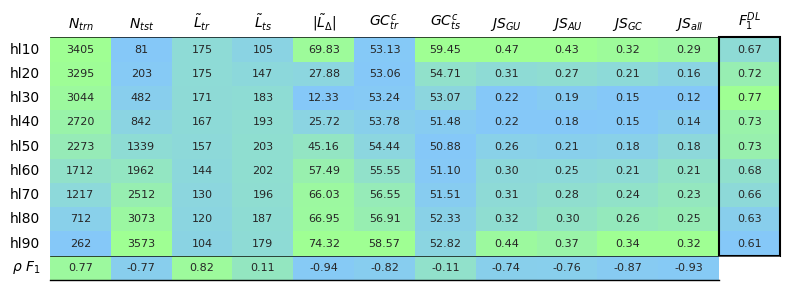

In [9]:
colors = ["#85C8F8", "#9FFF93"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("pastel_blue_to_yellow", colors)

# the same order
ttstats_norm = ttstats_norm.reindex(columns=cols_order)
ttstats_annot = ttstats_annot.reindex(columns=cols_order)
col_names = [name_mapping.get(col, col) for col in cols_order]

fig = plt.figure(figsize=(8, 3))
gs = gridspec.GridSpec(2, 1, height_ratios=[9, 1], hspace=0.0)
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])

# ==========================
# main heatmap
sns.heatmap(ttstats_norm, cmap=custom_cmap, annot=ttstats_annot,
            fmt='', linewidths=0, linecolor='black', cbar=False,
            annot_kws={'fontsize': 8}, ax=ax0)

ax0.set_xlabel('')
ax0.set_ylabel('')
ax0.tick_params(axis='x', top=False, labeltop=True, bottom=False, labelbottom=False, pad=0)
ax0.tick_params(axis='y', left=False, labelleft=True, right=False, labelright=False)
#ax0.set_xticks(ticks=np.arange(len(cols[0])) + 0.5)
ax0.set_xticklabels(col_names, rotation=0, ha='center')
ax0.set_yticklabels(ttstats_norm.index, rotation=0)
# table lines
for border_name, spine in ax0.spines.items():
    if (border_name == 'top'):
      spine.set_visible(True)
      spine.set_edgecolor('black')
      spine.set_linewidth(0.5)

# border around f1
f1_col_idx = ttstats_norm.columns.get_loc('f1')
rect = patches.Rectangle((f1_col_idx, 0), 1, len(ttstats_norm.index),
                          facecolor='none', edgecolor='black', linewidth=1.5,
                          clip_on=False)
ax0.add_patch(rect)


# ==========================
# correlations with F1
corrF1 = correlations.loc['f1', :]
corr_df = pd.DataFrame(corrF1.values.reshape(1, -1), columns=correlations.columns, index=['corr'])
corr_annot_df = corr_df.map(lambda x: f'{x:.2f}') # two decimal places
# mask to remove correlation of F1 with itself
mask_corr = pd.DataFrame(False, index=corr_df.index, columns=corr_df.columns)
mask_corr.loc['corr', 'f1'] = True

sns.heatmap(corr_df, cmap=custom_cmap, annot=corr_annot_df, fmt='',
            linewidths=0, linecolor='black', cbar=False, ax=ax1,
            vmin=-1, vmax=1, mask=mask_corr,
            annot_kws={'fontsize': 8})

ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.tick_params(axis='x', bottom=False, labelbottom=False, top=False, labeltop=False)
ax1.tick_params(axis='y', left=False, labelleft=True, right=False, labelright=False)
#ax1.set_yticks(ticks=[0.5]) # Center the y-tick for the single row
ax1.set_yticklabels(["$\\rho\\ F_1$"], rotation=0) # Set the y-label for the correlation row

# table lines
for border_name, spine in ax1.spines.items():
    if (border_name == 'top'):
      spine.set_visible(True)
      spine.set_edgecolor('black')
      spine.set_linewidth(0.5)

# no border under 'f1'
n_cols = len(corr_df.columns)
ax1.plot([0, n_cols - 1], [1, 1], color='black', linewidth=1.0, clip_on=False)

plt.tight_layout()

plt.savefig(FIG_PATH + "Table_S3.pdf", bbox_inches='tight', dpi=300)

# Family content

In [10]:
sorted_families = ['tRNA', '5s', 'tmRNA', 'RNaseP', 'srp', 'grp1', '23s', '16s', 'telomerase']

In [11]:
heatmap_data = pd.DataFrame(index=part10, columns=pd.MultiIndex.from_product([sorted_families, ['train', 'test']]), dtype=float)

for fold_name in part10:
    hl_fold = splits_hlfold.loc[splits_hlfold['fold_name'] == fold_name].copy()
    hl_fold['family'] = hl_fold.index.str.split('_').str[0]

    family_counts = hl_fold.groupby(['family', 'partition']).size().unstack(fill_value=0)
    for part in ['train', 'valid', 'test']:
        if part not in family_counts.columns:
            family_counts[part] = 0
    family_counts['train'] = family_counts['train'] + family_counts['valid']
    family_counts = family_counts[['train', 'test']]
    family_counts = family_counts.reindex(sorted_families)

    family_pct = family_counts / family_counts.sum() * 100
    for family in sorted_families:
        heatmap_data.loc[fold_name, (family, 'train')] = family_pct.loc[family, 'train']
        heatmap_data.loc[fold_name, (family, 'test')] = family_pct.loc[family, 'test']

# Family content

In [12]:
# proportion of test
test_pct_data = pd.DataFrame(index=part10, columns=sorted_families, dtype=float)

for fold_name in part10:
    print(f"Processing fold: {fold_name}")
    hl_fold = splits_hlfold.loc[splits_hlfold['fold_name'] == fold_name].copy()
    hl_fold['family'] = hl_fold.index.str.split('_').str[0]

    family_counts = hl_fold.groupby(['family', 'partition']).size().unstack(fill_value=0)
    for part in ['train', 'valid', 'test']:
        if part not in family_counts.columns:
            family_counts[part] = 0
    family_counts['train'] = family_counts['train'] + family_counts['valid']
    family_counts = family_counts[['train', 'test']]
    family_counts = family_counts.reindex(sorted_families, fill_value=0)

    family_totals = family_counts.sum(axis=1)
    test_pct_data.loc[fold_name] = (family_counts['test'] / family_totals * 100)
    #print(family_counts)

# transpose so rows are families
test_pct_data_T = test_pct_data.T

Processing fold: hl10
Processing fold: hl20
Processing fold: hl30
Processing fold: hl40
Processing fold: hl50
Processing fold: hl60
Processing fold: hl70
Processing fold: hl80
Processing fold: hl90


In [13]:
# average F1 per family, per fold
data_fam = data.copy()
data_fam['family'] = data_fam.index.str.split('_').str[0]
# family derived from the sequence id in the index
f1_data = data_fam.groupby(['fold', 'family'])['f1'].mean().unstack('family')
f1_data = f1_data.reindex(index=part10, columns=sorted_families)

f1_data_T = f1_data.T

In [14]:
# average F1 per family, per fold, for RNAfold
data_rna = summary_hlfold[summary_hlfold["method"] == "RNAfold"].copy()
data_rna['family'] = data_rna.index.str.split('_').str[0]
f1_rna_data = data_rna.groupby(['fold', 'family'])['f1'].mean().unstack('family')
f1_rna_data = f1_rna_data.reindex(index=part10, columns=sorted_families)

f1_rna_data_T = f1_rna_data.T

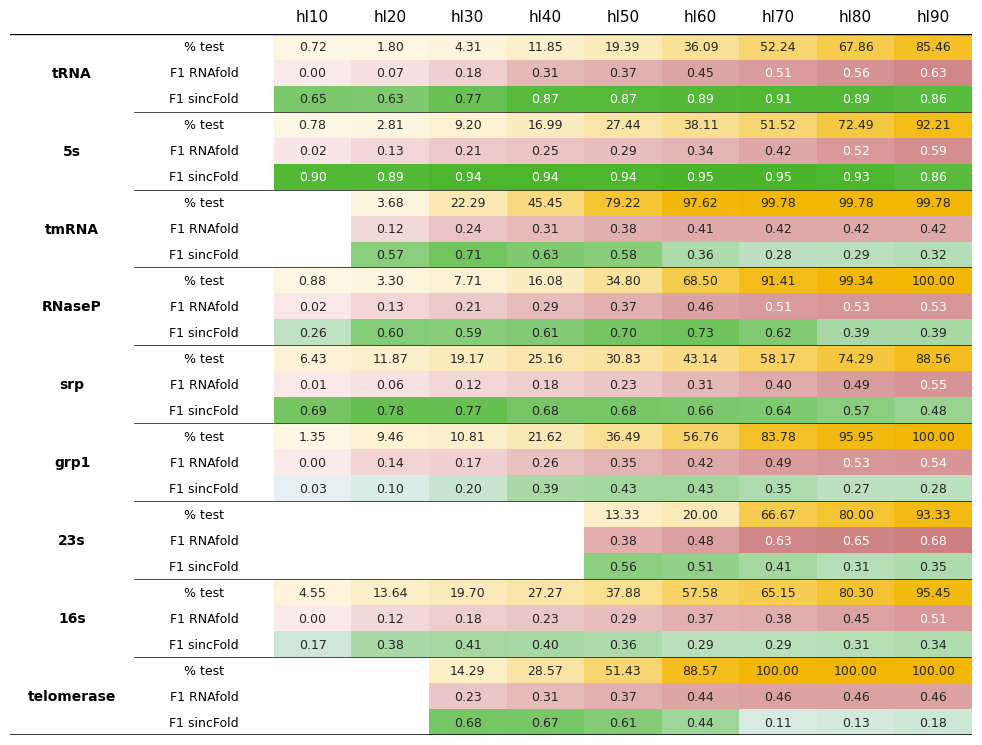

In [15]:
n_families = len(sorted_families)
rows_per_family = 3
n_rows = rows_per_family * n_families
n_folds = len(part10)

metric_names = []
for i in range(n_families):
    metric_names.append('% test')
    metric_names.append('F1 RNAfold')
    metric_names.append('F1 sincFold')

test_layer = pd.DataFrame(np.nan, index=range(n_rows), columns=part10)
sinc_layer = pd.DataFrame(np.nan, index=range(n_rows), columns=part10)
rna_layer = pd.DataFrame(np.nan, index=range(n_rows), columns=part10)

for i, family in enumerate(sorted_families):
    test_layer.iloc[rows_per_family * i] = test_pct_data_T.loc[family].values
    rna_layer.iloc[rows_per_family * i + 1] = f1_rna_data_T.loc[family].values
    sinc_layer.iloc[rows_per_family * i + 2] = f1_data_T.loc[family].values

def format_test(x):
    if pd.isna(x):
        return ''
    elif x == 0:
        return ''
    else:
        return f'{x:.2f}'

def format_f1(x):
    if pd.isna(x):
        return ''
    else:
        return f'{x:.2f}'

test_annot = test_layer.map(format_test)
sinc_annot = sinc_layer.map(format_f1)
rna_annot = rna_layer.map(format_f1)

is_test_na = test_layer.isna()
is_test_zero = test_layer == 0
mask_test = is_test_na | is_test_zero

mask_sinc = sinc_layer.isna()
mask_rna = rna_layer.isna()

yellow_cmap = mcolors.LinearSegmentedColormap.from_list("pastel_yellow", ["#FDF6E3", "#F2B705"])
blue_cmap = mcolors.LinearSegmentedColormap.from_list("pastel_blue", ["#EAF2FB", "#41B21F"])
red_cmap = mcolors.LinearSegmentedColormap.from_list("pastel_red", ["#FBEAEA", "#B84D4D"])

# separate axes for the family names
fig = plt.figure(figsize=(0.8 * (n_folds + 3.4), 0.28 * n_rows))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.6, 1.8, n_folds], wspace=0.0)
ax_family = fig.add_subplot(gs[0])
ax_metric = fig.add_subplot(gs[1])
ax_data = fig.add_subplot(gs[2])

sns.heatmap(test_layer, cmap=yellow_cmap, annot=test_annot, fmt='',
            linewidths=0, cbar=False, ax=ax_data, mask=mask_test,
            annot_kws={'fontsize': 9})
sns.heatmap(rna_layer, cmap=red_cmap, annot=rna_annot, fmt='',
            linewidths=0, cbar=False, ax=ax_data, mask=mask_rna,
            vmin=0, vmax=1, annot_kws={'fontsize': 9})
sns.heatmap(sinc_layer, cmap=blue_cmap, annot=sinc_annot, fmt='',
            linewidths=0, cbar=False, ax=ax_data, mask=mask_sinc,
            vmin=0, vmax=1, annot_kws={'fontsize': 9})

ax_data.set_xlabel('')
ax_data.set_ylabel('')
ax_data.tick_params(axis='x', top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=11)
ax_data.tick_params(axis='y', left=False, labelleft=False)
ax_data.set_xticklabels(part10, rotation=0, ha='center')

# metric names
ax_metric.set_xlim(0, 1)
ax_metric.set_ylim(n_rows, 0)
ax_metric.axis('off')
for i, label in enumerate(metric_names):
    ax_metric.text(0.5, i + 0.5, label, ha='center', va='center', fontsize=9)

# family names
ax_family.set_xlim(0, 1)
ax_family.set_ylim(n_rows, 0)
ax_family.axis('off')
for i, family in enumerate(sorted_families):
    y_center = rows_per_family * i + rows_per_family / 2
    ax_family.text(0.5, y_center, family, ha='center', va='center', fontsize=10, fontweight='bold')

# separating lines between families
for idx in range(1, n_families):
    ax_data.axhline(idx * rows_per_family, color='black', linewidth=0.5)
    ax_metric.axhline(idx * rows_per_family, color='black', linewidth=0.5)

# lines below the hl header row and at the bottom of the table
ax_data.axhline(0, color='black', linewidth=1)
ax_data.axhline(n_rows, color='black', linewidth=1.1)
ax_metric.axhline(0, color='black', linewidth=1)
ax_metric.axhline(n_rows, color='black', linewidth=1.1)
ax_family.axhline(0, color='black', linewidth=1)
ax_family.axhline(n_rows, color='black', linewidth=1.1)

plt.tight_layout()
plt.savefig(FIG_PATH + "Table_S2.pdf", bbox_inches='tight', dpi=300)
plt.show()